# SimSiam health forecasting within a clip

A direct forecast improved 16-minibatch global SSL-loss prediction. Recursive forecasts accumulated error, and the timing selectors did not establish an adaptive gain over fixed timing. The SSL-loss oracle identified a repeatable timing opportunity in these three seeds, especially on later frames of the same clip.


## Experiment

The first analysis uses 192 original SimSiam branches out to 16 minibatches, including continuous updates. The second uses the 600 eight-minibatch timing branches with five paired draws and one update per non-Skip branch. Each collection fits its own Ridge and random forest models. In each fold, one entire source seed and all of its clip identities are held out. Model settings are fixed. The 24 clips originate from three independent source seeds.

**Inputs at the origin** are pixel redundancy and embedding similarity from the observed prefix, clip position, the previous training loss and gradient norm, the Adam first moment summary, and the initial historical-bank health. The input includes the candidate action schedule and elapsed minibatches. The local bank consists of future frames in the same clip and enters only as a prediction target. Global bank metrics likewise enter only as targets.

**Recursive forecasting** predicts the next change and adds it to the previous predicted change. **Direct forecasting** estimates the cumulative change from the origin for each action prefix. Skip leaves health unchanged in both. The one-step diagnostic uses observed previous health and is labeled dashed in the figure. The action mean baseline accumulates the average training-fold change per update type. Persistence predicts zero change.

Report raw and centered RankMe, feature variance, SSL loss and retrieval margin on all three banks. LiDAR is available in the V2 timing branches. The analyses are retrospective and use the saved paired training trajectories.


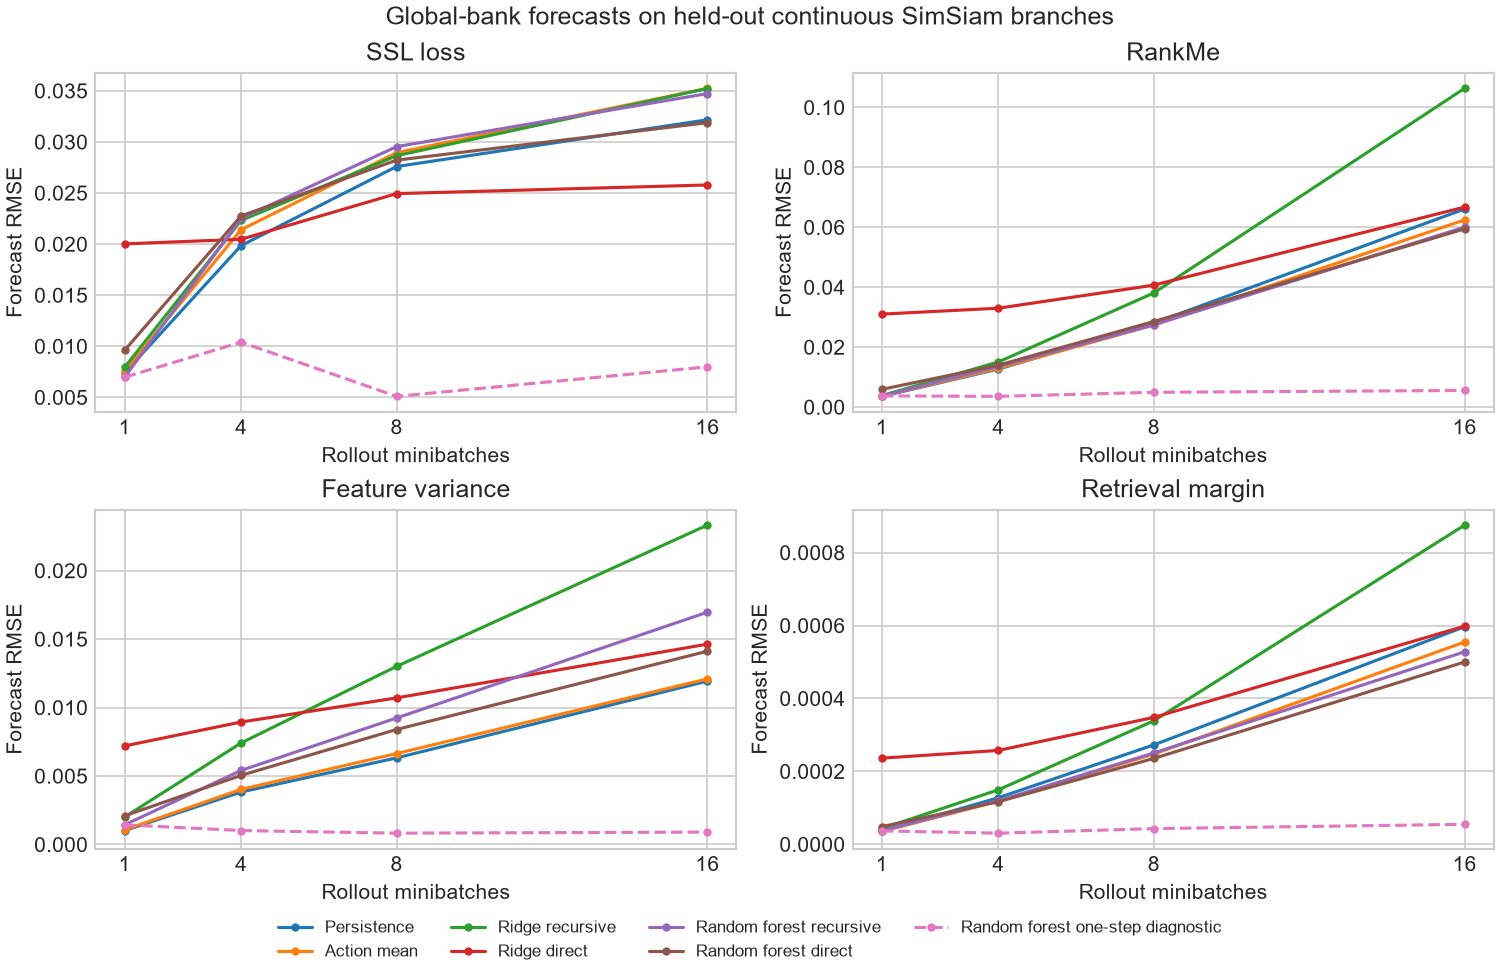

## Global-bank error after 16 consecutive updates

| Forecast | SSL loss | RankMe | Centered RankMe | Feature variance | Retrieval margin |
| --- | --- | --- | --- | --- | --- |
| Persistence | 0.032164 | 0.066117 | 0.16521 | 0.011931 | 0.00059663 |
| Action mean | 0.035246 | 0.062448 | 0.15938 | 0.01209 | 0.0005548 |
| Ridge recursive | 0.035227 | 0.10639 | 0.37328 | 0.023324 | 0.00087545 |
| Ridge direct | 0.025785 | 0.066742 | 0.21715 | 0.014629 | 0.00059824 |
| Random forest recursive | 0.03473 | 0.060056 | 0.223 | 0.016964 | 0.00052786 |
| Random forest direct | 0.031884 | 0.059477 | 0.18536 | 0.014114 | 0.00049995 |
| Random forest one-step diagnostic | 0.0079837 | 0.0055449 | 0.013176 | 0.00090362 | 5.4722e-05 |

Direct Ridge lowered the SSL-loss RMSE from 0.03216 to 0.02578 against persistence. The recursive models both exceeded the persistence error on SSL loss at this horizon. Direct random forest slightly improved raw RankMe and retrieval-margin error over the action mean. Centered RankMe and feature variance were harder to forecast. The low one-step diagnostic errors show what happens when the current health is supplied at each step.


## Timing decisions and the fixed baseline

A predictor scores the four single-update timings from the same origin, then selects the highest predicted utility. The comparison timing is selected using the other source seeds. The offline oracle selects on the other four augmentation draws of the same state and evaluates the fifth. Zero represents the fixed timing. Positive values favor the selector; for SSL loss they mean a reduction.

| Endpoint target | Ridge recursive | Ridge direct | Random forest recursive | Random forest direct | Independent-draw oracle |
| --- | --- | --- | --- | --- | --- |
| Global LiDAR | +0 | +0 | -0.00091683 | -0.00069453 | +0.00028351 |
| Global Retrieval margin | +2.5535e-06 | +0 | +1.0768e-06 | -1.1209e-06 | +6.9336e-06 |
| Local SSL loss | +0.0024642 | +0 | +0.0020789 | -0.00052158 | +0.0079108 |
| Historical SSL loss | +0.00019873 | -0.00014762 | -0.00011021 | -2.3832e-06 | +0.0024109 |
| Global SSL loss | +0.0012101 | +0 | +0.0015737 | +0.00073512 | +0.0062137 |
| Global RankMe | +0.00019635 | +0 | +5.7236e-05 | +1.715e-05 | +0.00046798 |

Ridge selected the first minibatch for all LiDAR decisions and tied the fixed baseline. Its positive local-loss result came from always updating at the eighth minibatch. The SSL-loss oracle reduced endpoint loss across all three source seeds on every bank. The learned timing choices did not consistently recover it. Error bars use a descriptive bootstrap over the three source seeds.


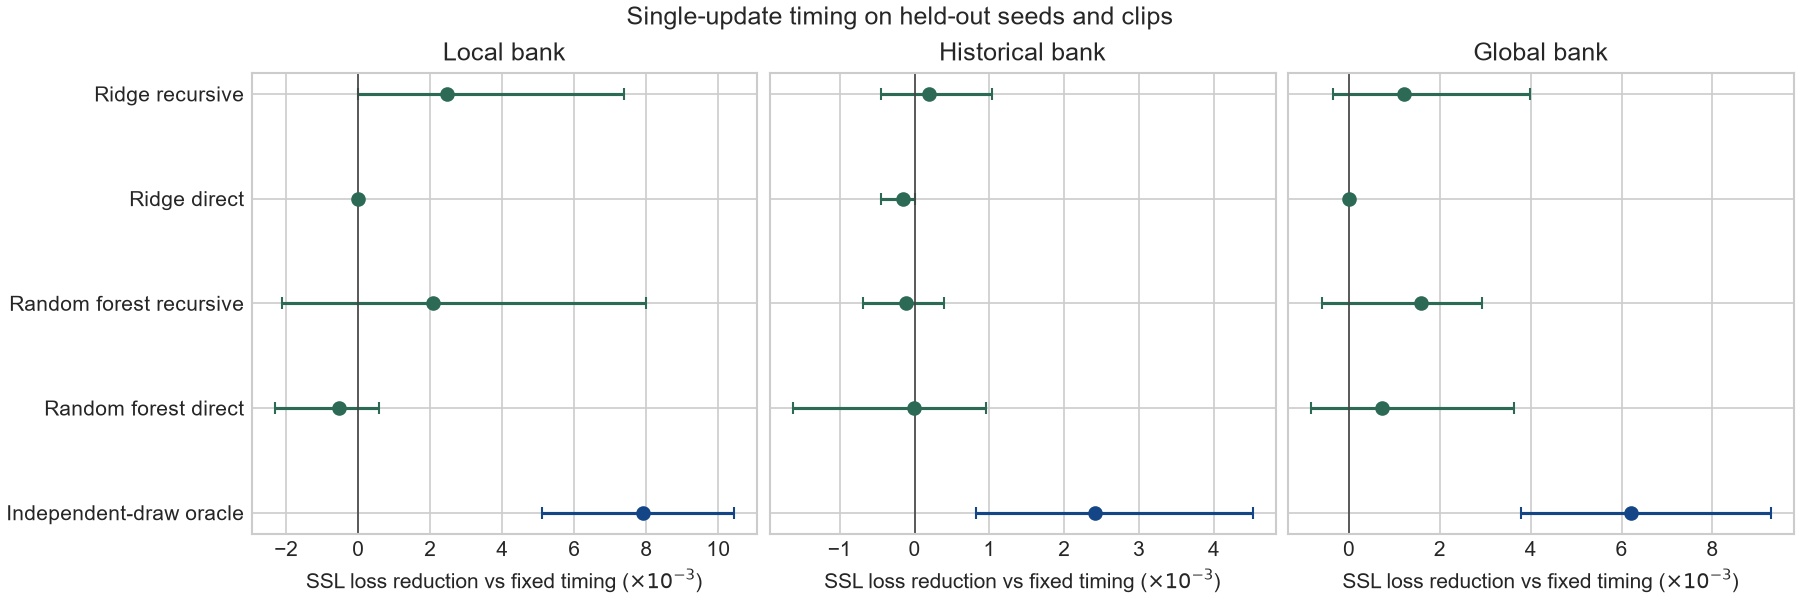

## What the data can establish

The continuous branches measure forecast error as real updates accumulate. The fresh-draw timing branches have one optimizer update, so timing selection here cannot establish interactions between updates. This pilot holds the prefix context fixed. It provides evidence about forecasting from the origin and does not test any strategy that scores a newly arrived minibatch before deciding whether to train on it.

Full per-bank scores, seed-level timing effects and decisions are in `forecast-summary.json` beside the runner.
